# 01 · Data exploration & cleaning - Stanford Online Products

**Project:** Visual Product Similarity & Image-Based Recommendation System (Amazon-style)

**Dataset:** [Stanford Online Products](https://www.tensorflow.org/datasets/catalog/stanford_online_products)
(Song et al., CVPR 2016) - product photos collected from **eBay listings**. Every listing
(= product) was photographed several times, which gives two levels of ground truth:

* **category** (12 super-classes: bicycle, chair, mug, ...)
* **product** (the individual eBay listing - several photos each)

That makes it a much better test bed than a plain category dataset: I can check whether the
system finds *the same product* from a different photo, not just "another chair".

In this notebook I:
1. explore the official test split
2. find and fix data-quality problems
3. run the cleaning module (`src/data_cleaning.py`)
4. load the clean catalog into a normalised SQLite database (`src/database.py`)

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import config
from src import data_cleaning, database

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 70)
print("Dataset root:", config.SOP_ROOT)

Dataset root: C:\Users\kisho\Documents\Guvi\Project_4\data\raw\Stanford_Online_Products


## 1. The raw dataset

In [2]:
splits = {name: pd.read_csv(config.SOP_ROOT / f"Ebay_{name}.txt", sep=" ") for name in ["train", "test"]}
pd.DataFrame({name: {"images": len(df), "products": df["class_id"].nunique(),
                     "categories": df["super_class_id"].nunique()}
              for name, df in splits.items()}).T

,images,products,categories
train,59551,11318,12
test,60502,11316,12


The official protocol uses disjoint products for train and test. I don't train a model - I use
an ImageNet-pretrained CNN as-is - so I work with the **test split (60,502 images, 11,316
products)**, the standard retrieval benchmark. That is 60× the brief's 1,000-image minimum.

In [3]:
raw = data_cleaning.load_sop_index(config.SOP_ROOT, "test")
raw.head()

,image_id,class_id,category,product_id,view,source_path
0,59552,11319,bicycle,251952414262,0,bicycle_final/251952414262_0.JPG
1,59553,11319,bicycle,251952414262,1,bicycle_final/251952414262_1.JPG
2,59554,11319,bicycle,251952414262,2,bicycle_final/251952414262_2.JPG
3,59555,11319,bicycle,251952414262,3,bicycle_final/251952414262_3.JPG
4,59556,11319,bicycle,251952414262,4,bicycle_final/251952414262_4.JPG


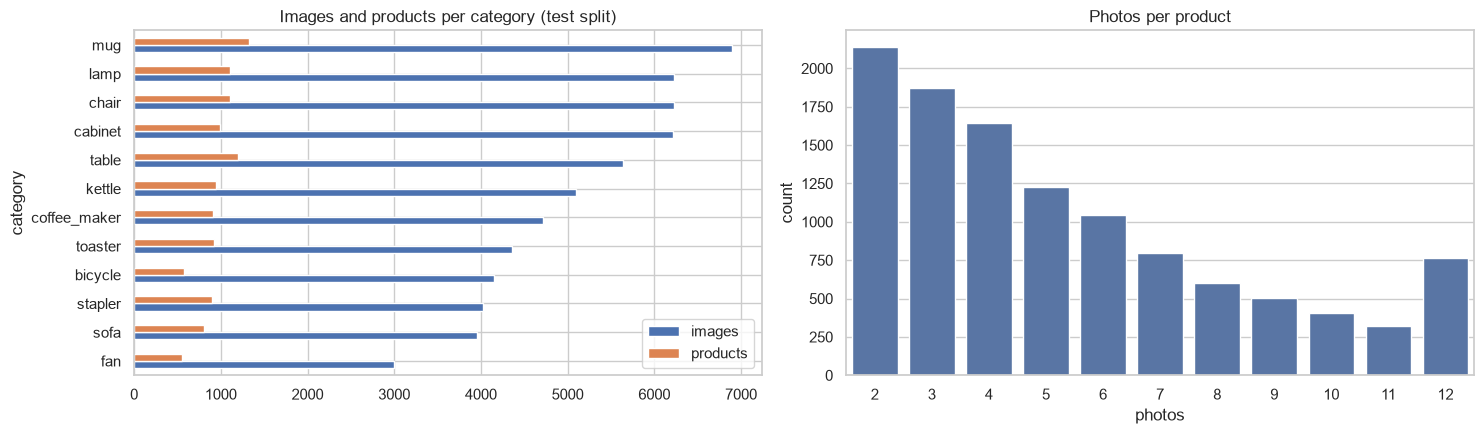

Photos per product: min=2, median=4.5, max=12


,images,products,photos_per_product
category,,,
bicycle,4145,574,7.22
cabinet,6220,988,6.30
chair,6226,1107,5.62
coffee_maker,4713,911,5.17
fan,3003,550,5.46
kettle,5101,949,5.38
lamp,6226,1108,5.62
mug,6895,1320,5.22
sofa,3959,802,4.94


In [4]:
per_cat = raw.groupby("category").agg(images=("image_id", "size"), products=("product_id", "nunique"))
per_cat["photos_per_product"] = (per_cat["images"] / per_cat["products"]).round(2)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
per_cat[["images", "products"]].sort_values("images").plot.barh(ax=axes[0])
axes[0].set_title("Images and products per category (test split)")
photos = raw.groupby("product_id").size()
sns.countplot(x=photos, ax=axes[1], color="#4C72B0")
axes[1].set_title("Photos per product")
axes[1].set_xlabel("photos")
plt.tight_layout()
plt.show()
print(f"Photos per product: min={photos.min()}, median={photos.median()}, max={photos.max()}")
per_cat

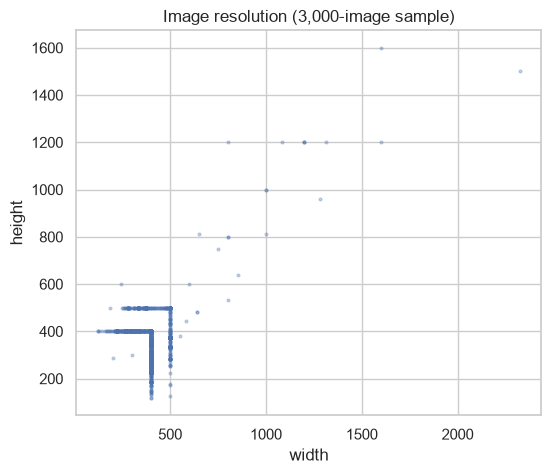

Colour modes: {'RGB': 2985, 'L': 15}
          min    50%     max
width   121.0  400.0  2327.0
height  119.0  375.0  1600.0


In [5]:
rng = np.random.default_rng(0)
sample = raw.sample(3000, random_state=0)
info = []
for p in sample["source_path"]:
    with Image.open(config.SOP_ROOT / p) as img:   # header only - fast
        info.append((*img.size, img.mode))
info = pd.DataFrame(info, columns=["width", "height", "mode"])

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(info["width"], info["height"], s=4, alpha=0.3)
ax.set_xlabel("width"); ax.set_ylabel("height")
ax.set_title("Image resolution (3,000-image sample)")
plt.show()
print("Colour modes:", info["mode"].value_counts().to_dict())
print(info[["width", "height"]].describe().loc[["min", "50%", "max"]].T)

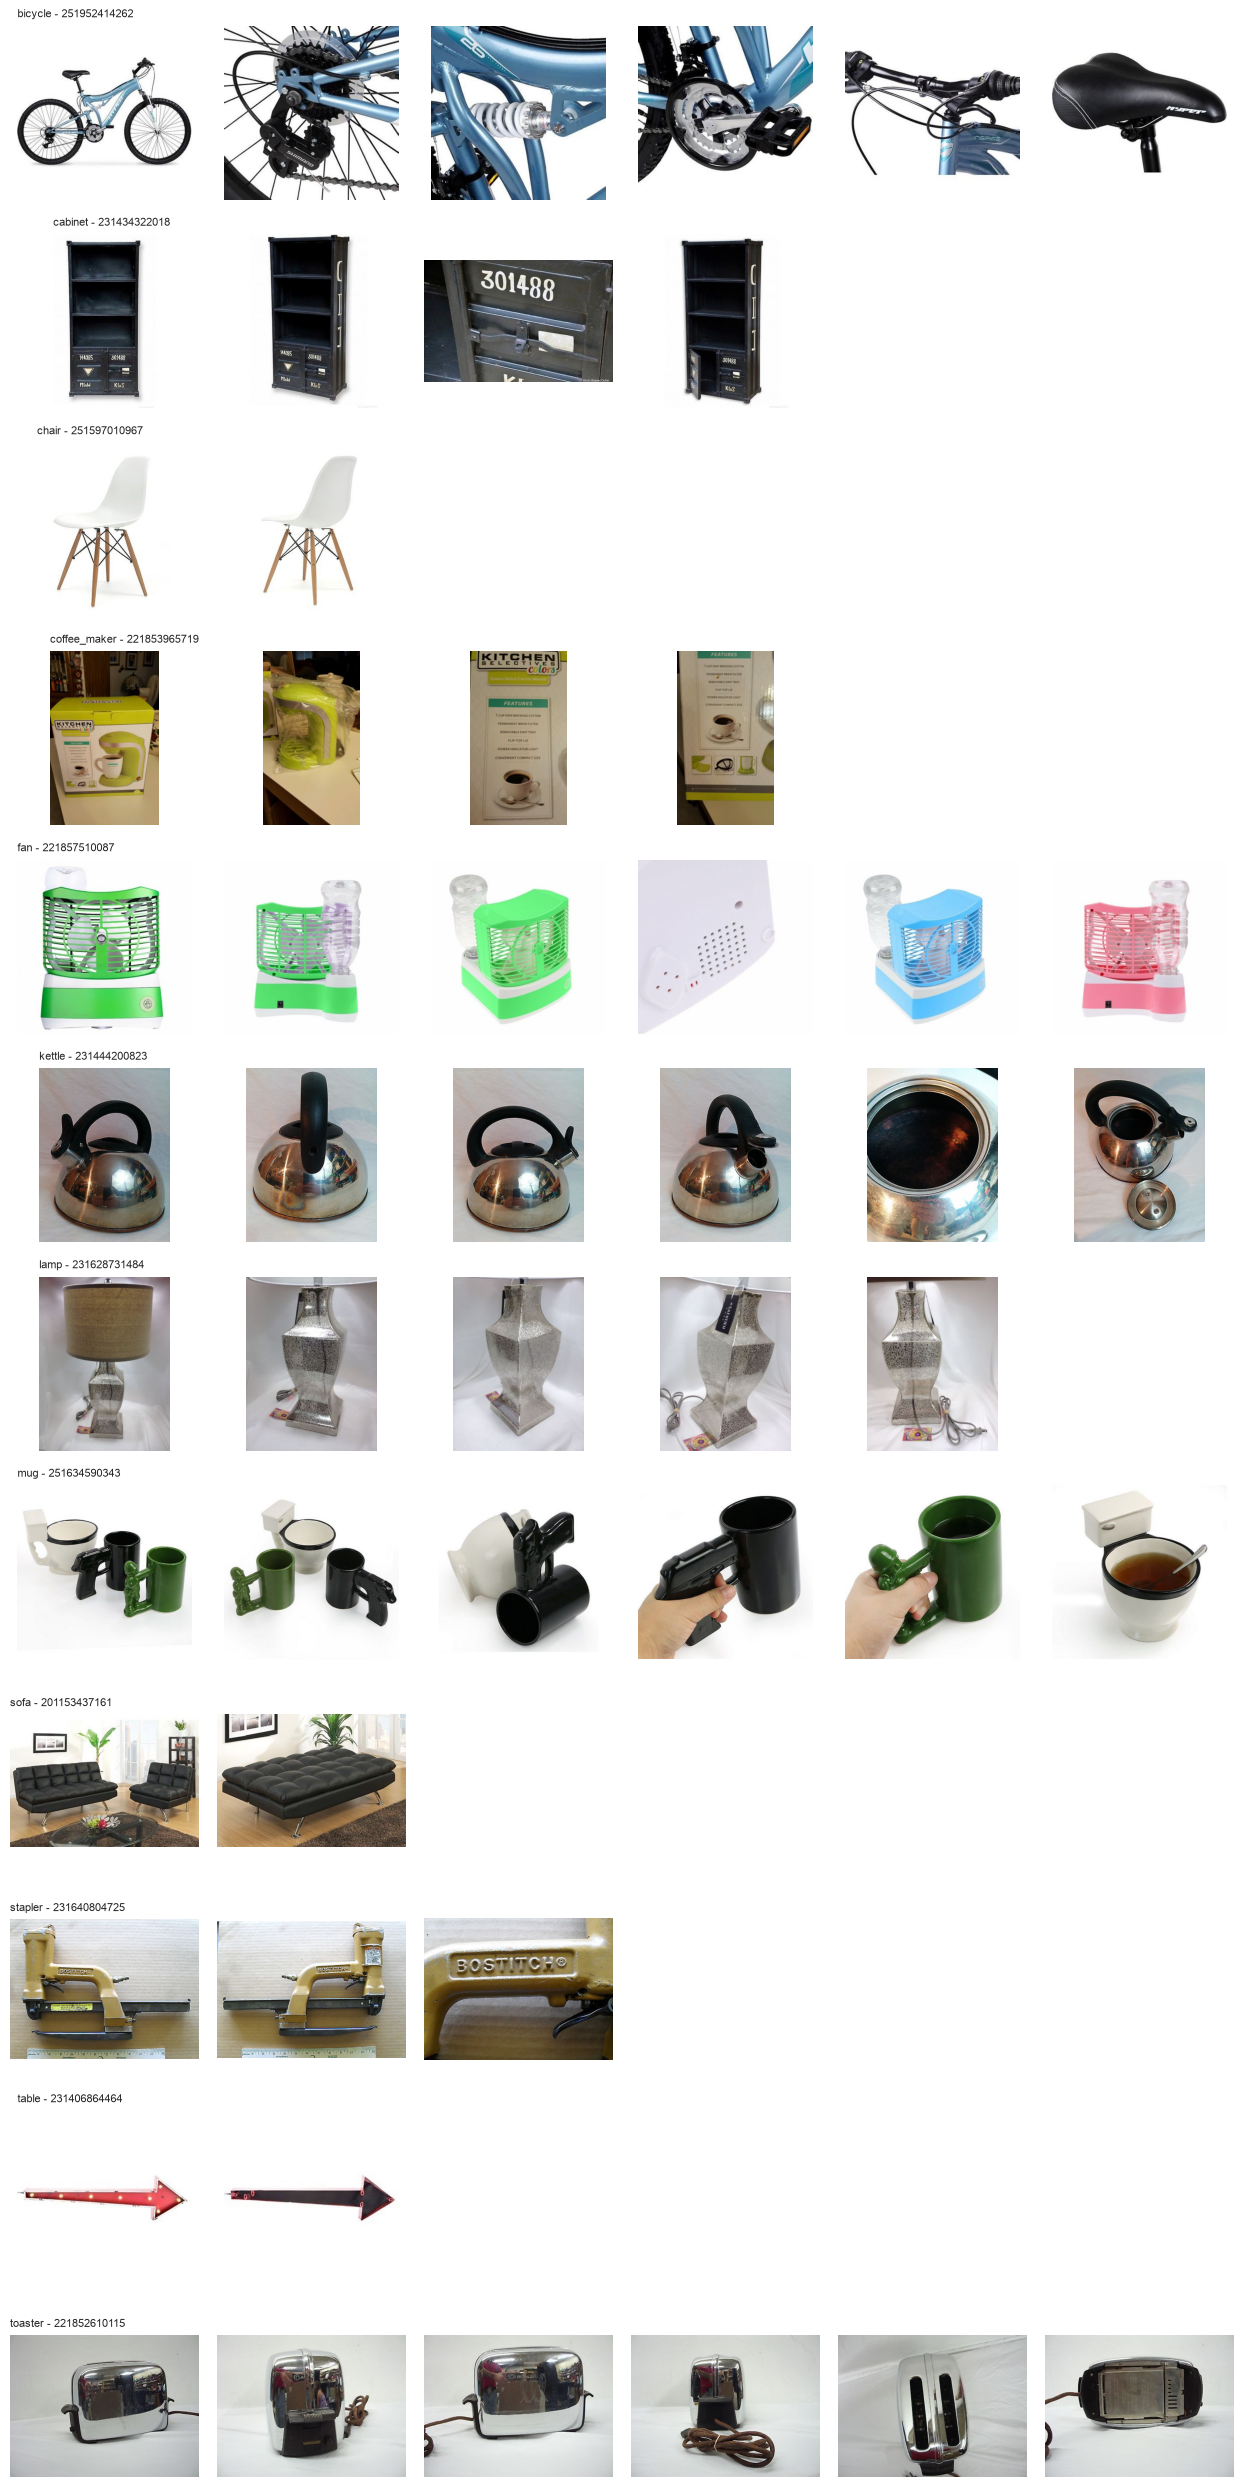

In [6]:
def show_product_rows(products, max_views=6, size=2.1):
    fig, axes = plt.subplots(len(products), max_views, figsize=(size * max_views, size * len(products)))
    for r, (pid, group) in enumerate(products):
        for c in range(max_views):
            ax = axes[r, c]
            ax.axis("off")
            if c < len(group):
                with Image.open(config.SOP_ROOT / group["source_path"].iloc[c]) as img:
                    ax.imshow(img.convert("RGB"))
                if c == 0:
                    ax.set_title(f"{group['category'].iloc[0]} - {pid}", fontsize=8, loc="left")
    plt.tight_layout()
    plt.show()

one_per_category = [next(iter(g.groupby("product_id"))) for _, g in raw.groupby("category")]
show_product_rows(one_per_category)

**Observations**

* Real marketplace photos: mostly product-centric, but backgrounds vary from white studio
  shots to living rooms, lawns and garages - exactly the noisy conditions a marketplace has.
* Each row is **one product**: the photos show different angles, close-ups (a saddle, a
  label) and packaging. Recognising these as the same item is genuinely hard.
* Resolution varies (most images are ≤ 500 px); a small share are greyscale (`L`) and need
  converting to RGB before going into a CNN.

## 2. Data-quality checks

`src/data_cleaning.py` runs these checks on every image in parallel worker processes:

| Check | Why |
|---|---|
| file decodes fully | corrupt or truncated downloads |
| min side ≥ 64 px | thumbnails / thin slivers |
| pixel std-dev ≥ 2 | blank images (failed uploads) |
| convert to RGB, resize to ≤ 320 px | uniform input; 224 px is all the CNN needs |
| near-duplicate removal | sellers re-upload the same photo |

**Duplicate detection at scale.** Comparing every pair of 60k images is 1.8 billion
comparisons. I compute a 64-bit **difference hash** per image and use the pigeonhole
principle: split the hash into 5 chunks - if two hashes differ in ≤ 4 bits, at least one
chunk is identical, so only images that share a chunk need comparing.

**Why the hash alone is not enough.** I first confirmed candidates with a greyscale pixel
check and visually reviewed the results: the dHash is computed in greyscale, so a **red and a
blue version of the same sofa** looked identical and were being deleted. Those are exactly
the products a visual-similarity system must keep apart. A *mean* colour difference didn't
fix it either - a colour variant only changes part of the frame. The final rule: a candidate
is a duplicate only if **no pixel** of the 16×16 colour thumbnails differs by more than 48
levels. Reviewing the pairs, everything above that threshold was a colour variant or a
different product.

## 3. Run the cleaning pipeline

In [7]:
%%time
products, images, log = data_cleaning.clean_dataset()

CPU times: total: 5.44 s
Wall time: 55.4 s


In [8]:
reasons = log["reason"].fillna("").replace("", "kept").str.replace(r" of .*", "", regex=True)
summary = reasons.value_counts().rename("images").to_frame()
summary["share"] = (summary["images"] / len(log)).map("{:.2%}".format)
print(f"Kept {len(images):,} of {len(log):,} images | {len(products):,} products | "
      f"{products['category'].nunique()} categories")
summary

Kept 58,891 of 60,502 images | 11,311 products | 12 categories


,images,share
reason,,
kept,58891,97.34%
near-duplicate (same product),1536,2.54%
near-duplicate (other product),71,0.12%
too small (400x63),1,0.00%
near-uniform / blank image,1,0.00%
too small (53x500),1,0.00%
too small (54x400),1,0.00%


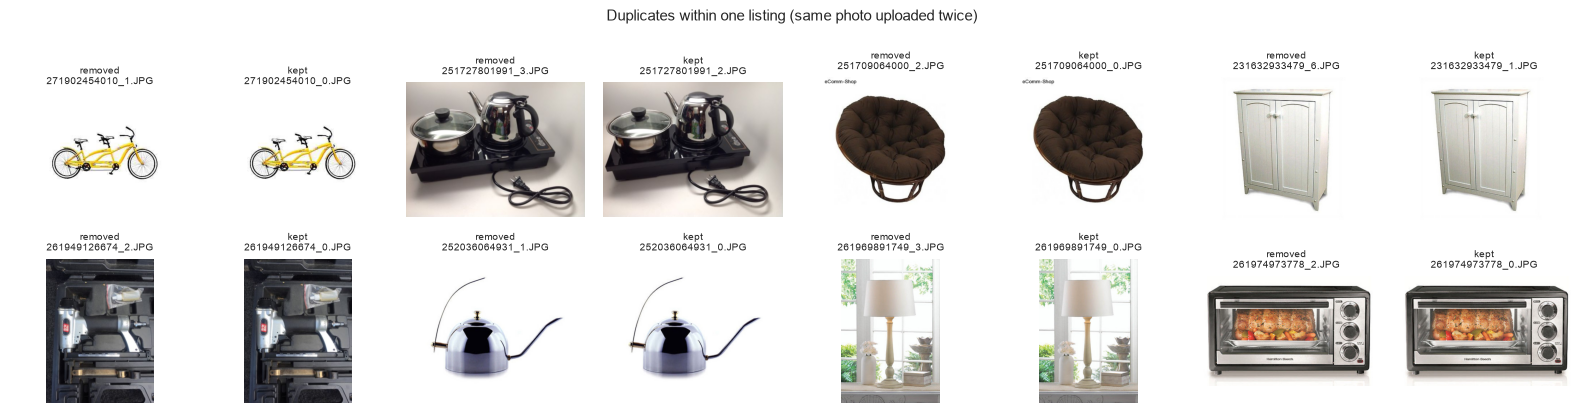

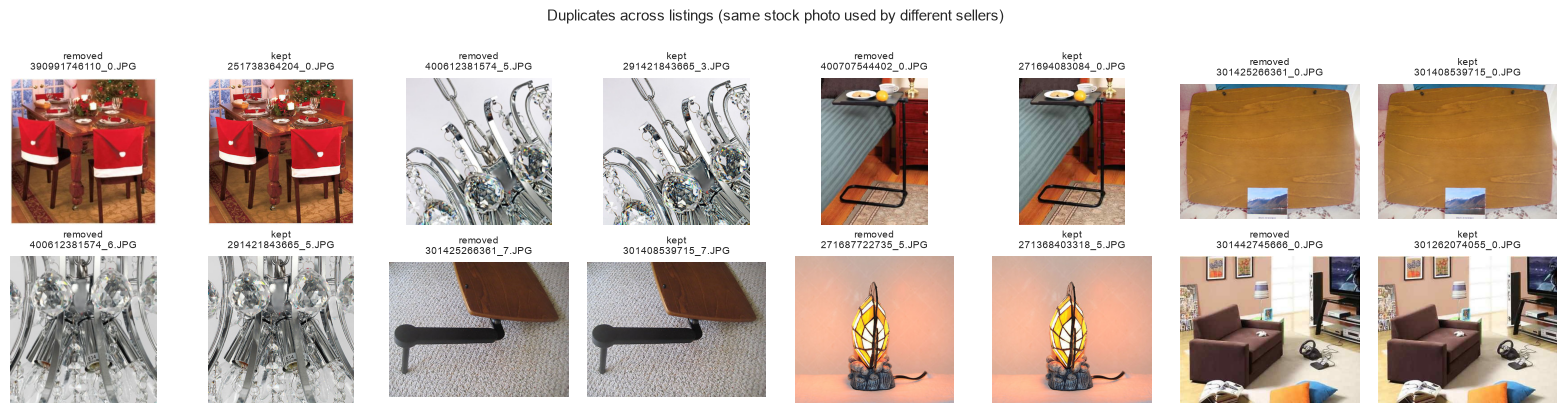

In [9]:
from PIL import Image as PILImage
dups = log[log["reason"].fillna("").str.startswith("near-duplicate")].copy()
dups["original"] = dups["reason"].str.split(" of ").str[1]
source_of = log.set_index("file_name")["image_id"]
raw_path = raw.set_index("image_id")["source_path"]

def show_pairs(pairs, title, ncols=4, labels=("removed", "kept")):
    n = len(pairs)
    fig, axes = plt.subplots(int(np.ceil(n / ncols)), ncols * 2, figsize=(2 * ncols * 2, 2.1 * np.ceil(n / ncols)))
    for ax in np.ravel(axes):
        ax.axis("off")
    for i, (a, b) in enumerate(pairs):
        for j, iid in enumerate([a, b]):
            ax = np.ravel(axes)[i * 2 + j]
            with PILImage.open(config.SOP_ROOT / raw_path[iid]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(labels[j] + f"\n{raw_path[iid].split('/')[1][:18]}", fontsize=7)
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    plt.show()

same = dups[dups["reason"].str.contains("same product")].sample(8, random_state=1)
show_pairs([(r.image_id, source_of[r.original]) for r in same.itertuples()],
           "Duplicates within one listing (same photo uploaded twice)")
cross = dups[dups["reason"].str.contains("other product")].sample(8, random_state=1)
show_pairs([(r.image_id, source_of[r.original]) for r in cross.itertuples()],
           "Duplicates across listings (same stock photo used by different sellers)")

Both kinds are real: sellers upload the same photo twice inside one listing, and different
listings re-use the same stock photo.

**Why removing them matters for evaluation:** my protocol is leave-one-out - every photo
queries the rest of the catalog. An identical copy of the query sitting in the catalog would
be found at rank 1 for free and inflate Product Recall@1. Cross-listing copies are worse: they
are identical images labelled as *different* products, i.e. guaranteed errors.

### What the colour check saved

Candidate pairs that matched on the hash but **failed** the colour check - all of these are
still in the catalog:

Kept-image pairs that a hash-only rule would have deleted: 1,205


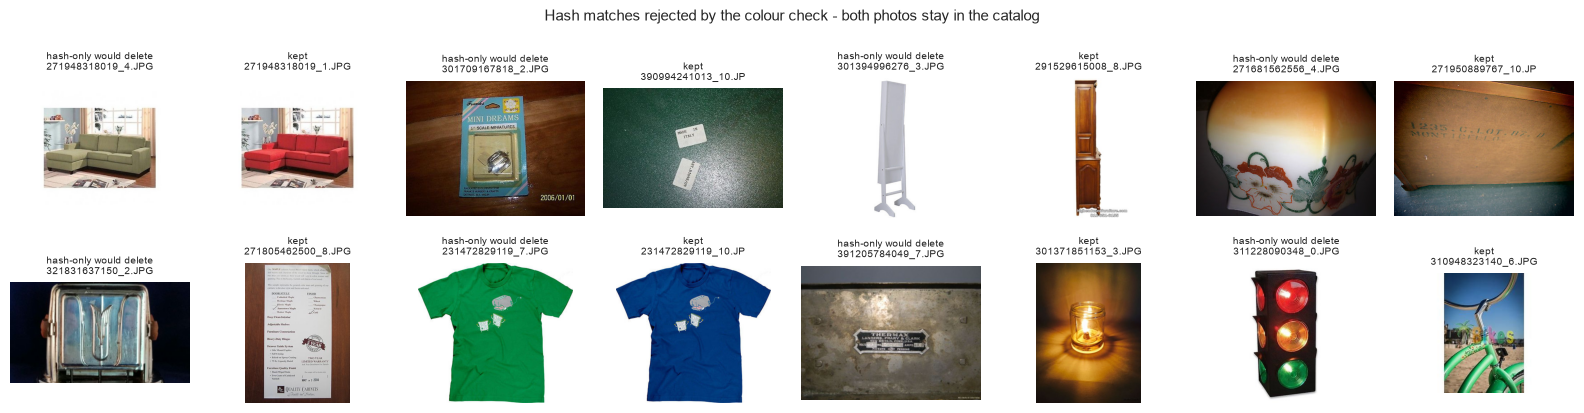

In [10]:
kept_hashes = np.array([int(h, 16) for h in images["dhash"]], dtype=np.uint64)
dummy = np.zeros((len(images), 1, 1, 3), dtype=np.uint8)          # accept every hash candidate
hash_only = data_cleaning.find_duplicates(kept_hashes, dummy, max_pixel_diff=255)
print(f"Kept-image pairs that a hash-only rule would have deleted: {len(hash_only):,}")

pairs = list(hash_only.items())
pick = np.random.default_rng(4).choice(len(pairs), 8, replace=False)
show_pairs([(images.at[pairs[i][0], "image_id"], images.at[pairs[i][1], "image_id"]) for i in pick],
           "Hash matches rejected by the colour check - both photos stay in the catalog",
           labels=("hash-only would delete", "kept"))

Two kinds of false match show up:

* **Colour variants** - the same design in a different colour (green vs red sofa, green vs
  blue T-shirt). A shopper wants to see these side by side, not have one deleted.
* **Unrelated photos that collide by chance** - mostly dark or low-contrast shots (a traffic
  light vs a bicycle) whose coarse 9×8 brightness gradients happen to match.

Either way, a hash-only rule would have deleted 1,205 legitimate photos - almost as many as
the 1,607 real duplicates it finds. The pixel check is essential.

### Cleaning outcome per category

In [11]:
per_cat_clean = (log.assign(status=log["status"])
                 .groupby(["category", "status"]).size().unstack(fill_value=0))
per_cat_clean["removed_%"] = (100 * per_cat_clean["rejected"] / per_cat_clean.sum(axis=1)).round(2)
per_cat_clean["products"] = products.groupby("category").size()
per_cat_clean.sort_values("removed_%", ascending=False)

status,kept,rejected,removed_%,products
category,,,,
sofa,3768,191,4.82,801
lamp,5964,262,4.21,1107
fan,2879,124,4.13,550
table,5420,218,3.87,1193
bicycle,4035,110,2.65,574
cabinet,6061,159,2.56,988
kettle,4984,117,2.29,949
stapler,3929,90,2.24,893
toaster,4274,83,1.90,918


Removal rates are low (2.7 % overall) and fairly even across categories, so cleaning does not
skew the category balance. A handful of products lost all their photos (every photo was a
cross-listing duplicate), which is why 11,311 of 11,316 products remain.

## 4. Product metadata

The brief lists *(optional) filter by category, price range, or availability*. SOP ships
images and labels only, so I simulate price, rating and stock **per product** with a fixed seed
(reproducible) and category-specific, log-uniform price ranges (a sofa costs more than a mug).
This is clearly flagged as simulated in the app and README.

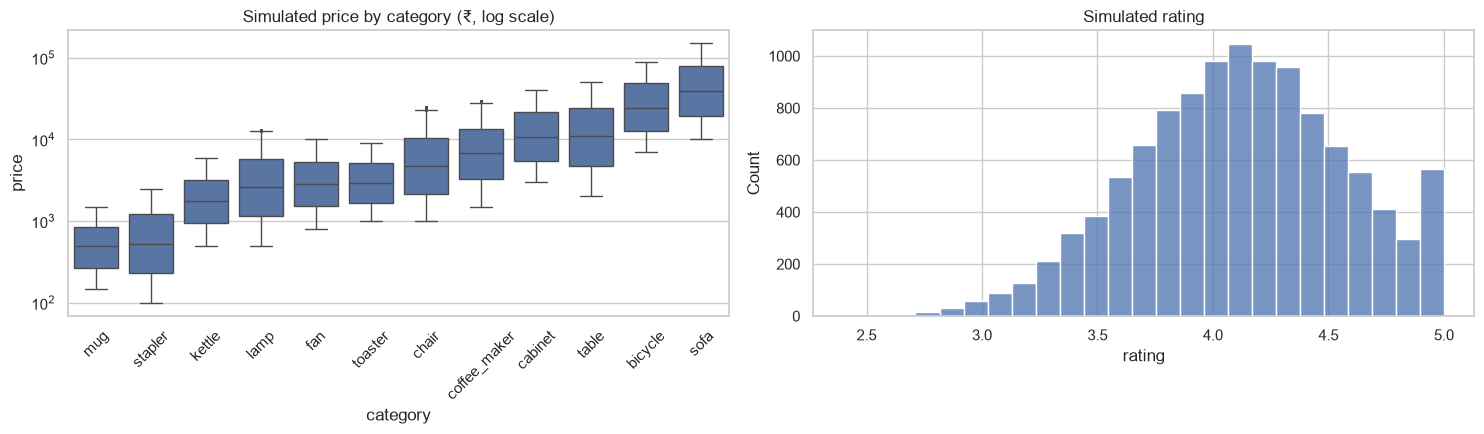

In stock: 88.1%


,product_id,class_id,category,num_images,main_image_id,product_name,price,rating,in_stock
0,251952414262,11319,bicycle,7,59552,Bicycle #0001,50529,3.6,True
1,251965640823,11320,bicycle,1,59559,Bicycle #0002,62719,4.5,True
2,251976734761,11321,bicycle,3,59564,Bicycle #0003,8899,3.5,True
3,251976765494,11322,bicycle,1,59569,Bicycle #0004,48899,4.0,False
4,251980479134,11323,bicycle,4,59574,Bicycle #0005,9709,3.7,False


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
order = products.groupby("category")["price"].median().sort_values().index
sns.boxplot(data=products, x="category", y="price", order=order, ax=axes[0], fliersize=1)
axes[0].set_yscale("log")
axes[0].set_title("Simulated price by category (₹, log scale)")
axes[0].tick_params(axis="x", rotation=45)
sns.histplot(products["rating"], bins=25, ax=axes[1])
axes[1].set_title("Simulated rating")
plt.tight_layout()
plt.show()
print(f"In stock: {products['in_stock'].mean():.1%}")
products.head()

## 5. Load into SQLite

```
categories       (category_id PK, category_name UNIQUE)
products         (product_id PK = eBay item id, sop_class_id UNIQUE, category_id FK,
                  product_name, price, rating, in_stock)
product_images   (image_id PK, product_id FK, view_index, image_file UNIQUE, sizes, hash)
embedding_models (model_id PK, model_name UNIQUE, embedding_dim, num_vectors)
image_embeddings (model_id FK, vector_row, image_id FK)   -- FAISS row -> photo -> product
search_logs      (search_id PK, query_type, model_name, latency_ms, ...)
```

A product has many photos (1:N), and FAISS stores one vector per photo; `image_embeddings`
maps a FAISS result row back to the photo and its product.

In [13]:
database.load_catalog(products, images)

with database.get_connection() as conn:
    objects = pd.read_sql_query("""SELECT type, name FROM sqlite_master
                                   WHERE type IN ('table','index') AND name NOT LIKE 'sqlite_%'
                                   ORDER BY type DESC, name""", conn)
    counts = {t: conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
              for t in ["categories", "products", "product_images"]}
print(counts)
objects

{'categories': 12, 'products': 11311, 'product_images': 58891}


,type,name
0,table,categories
1,table,embedding_models
2,table,image_embeddings
3,table,product_images
4,table,products
5,table,search_logs
6,index,idx_embeddings_image
7,index,idx_images_product
8,index,idx_products_category
9,index,idx_products_price


In [14]:
with database.get_connection() as conn:
    by_category = pd.read_sql_query("""
        SELECT c.category_name,
               COUNT(DISTINCT p.product_id)                          AS products,
               COUNT(i.image_id)                                     AS photos,
               ROUND(1.0 * COUNT(i.image_id) / COUNT(DISTINCT p.product_id), 2) AS photos_per_product,
               MIN(p.price) AS min_price, MAX(p.price) AS max_price
        FROM products p
        JOIN categories c      ON c.category_id = p.category_id
        JOIN product_images i  ON i.product_id  = p.product_id
        GROUP BY c.category_name
        ORDER BY products DESC""", conn)
by_category

,category_name,products,photos,photos_per_product,min_price,max_price
0,mug,1320,6821,5.17,149,1489
1,table,1193,5420,4.54,1999,49989
2,lamp,1107,5964,5.39,499,12999
3,chair,1107,6132,5.54,999,24979
4,cabinet,988,6061,6.13,3009,39879
5,kettle,949,4984,5.25,499,5979
6,toaster,918,4274,4.66,999,8999
7,coffee_maker,911,4624,5.08,1499,29949
8,stapler,893,3929,4.40,99,2479
9,sofa,801,3768,4.70,10029,149709


The filter query behind the app's paginated catalog - checking that SQLite uses the indexes:

In [15]:
with database.get_connection() as conn:
    plan = pd.read_sql_query("""
        EXPLAIN QUERY PLAN
        SELECT p.product_id FROM products p JOIN categories c ON c.category_id = p.category_id
        WHERE c.category_name = 'mug' AND p.price BETWEEN 200 AND 800 AND p.in_stock = 1""", conn)
plan[["detail"]]

,detail
0,SEARCH c USING COVERING INDEX sqlite_autoindex_categories_1 (categ...
1,SEARCH p USING INDEX idx_products_category (category_id=?)


In [16]:
import time
t0 = time.perf_counter()
page, total = database.get_catalog_page(categories=["mug"], price_range=(200, 800), in_stock_only=True, limit=5)
print(f"{total} in-stock mugs between ₹200 and ₹800 - page fetched in {(time.perf_counter() - t0) * 1000:.1f} ms")
page

687 in-stock mugs between ₹200 and ₹800 - page fetched in 5.6 ms


,product_id,product_name,category,price,rating,in_stock,image_file,num_images
0,251634590343,Mug #0001,mug,479,3.2,1,mug/251634590343_0.jpg,9
1,251654095413,Mug #0002,mug,489,3.9,1,mug/251654095413_0.jpg,4
2,251681034170,Mug #0004,mug,379,4.5,1,mug/251681034170_0.jpg,2
3,251694255883,Mug #0006,mug,689,3.9,1,mug/251694255883_0.jpg,2
4,251708184735,Mug #0007,mug,769,4.2,1,mug/251708184735_0.jpg,10


## Summary

| Step | Result |
|---|---|
| Source | SOP official test split - 60,502 images, 11,316 products, 12 categories |
| Corrupt / unreadable | 0 |
| Too small / blank | 4 |
| Re-used photos removed | 1,607 (1,536 within a listing, 71 across listings) |
| Colour variants protected | hash-only matching would have wrongly removed these (see above) |
| Clean catalog | **58,891 photos of 11,311 products** |
| Storage | SQLite, 6 tables, FK constraints + indexes on category / price / stock / product |

Next notebook: turn every photo into an embedding vector and index it with FAISS.